# Topic 22d - Multivariate exploration

The main lesson combined station type and month on one line chart. This notebook adds a heatmap grid (two categorical dimensions at once, reusing Topic 21's sequential-colour rule) and a three-variable scatter using colour as the third dimension.

Work through it after reading section 5 of the [main lesson](topic22_exploratory_data_analysis.ipynb).

In [1]:
# Run this cell as it is.
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def find_data_dir():
    """Locate the lesson's data folder from the repository root, the lesson
    folder, or the assignments folder, so this notebook runs from anywhere."""
    candidates = [
        Path.cwd() / "data",
        Path.cwd() / "exploratory_data_analysis" / "data",
        Path.cwd().parent / "data",
    ]
    for candidate in candidates:
        if (candidate / "air_quality_readings.csv").exists():
            return candidate
    raise FileNotFoundError(
        "Could not find air_quality_readings.csv. Looked in: " +
        ", ".join(str(c) for c in candidates)
    )


DATA_DIR = find_data_dir()

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 130)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.color"] = "#e1e0d9"
plt.rcParams["grid.linewidth"] = 0.8
plt.rcParams["axes.edgecolor"] = "#c3c2b7"
plt.rcParams["axes.axisbelow"] = True

# The course palette (Topic 21) - fixed hue order, never cycled, so a category
# keeps the same colour in every chart it appears in.
PALETTE = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
MUTED = "#c3c2b7"
INK = "#0b0b0b"
STATION_TYPE_COLOR = {
    "Roadside": PALETTE["red"], "Industrial": PALETTE["orange"],
    "Residential": PALETTE["aqua"], "Background": PALETTE["blue"],
}
STATION_TYPE_ORDER = ["Roadside", "Industrial", "Residential", "Background"]

WHO_ANNUAL_GUIDELINE = 5.0   # ug/m3, PM2.5 annual mean
WHO_24H_GUIDELINE = 15.0     # ug/m3, PM2.5 24-hour mean

print("pandas version:   ", pd.__version__)
print("data folder:      ", DATA_DIR)
print("files:            ", sorted(p.name for p in DATA_DIR.glob("*.csv")))

pandas version:    3.0.6
data folder:       /home/johnny/Projects/itfy-da/exploratory_data_analysis/data
files:             ['air_quality_readings.csv', 'air_quality_readings_assignment.csv', 'air_quality_stations.csv', 'air_quality_stations_assignment.csv', 'customers.csv', 'monthly_targets_wide.csv', 'orders.csv', 'products.csv', 'regions.csv', 'returns.csv']


In [2]:
stations = pd.read_csv(DATA_DIR / "air_quality_stations.csv")
readings = pd.read_csv(DATA_DIR / "air_quality_readings.csv", parse_dates=["date"])

aq = readings.merge(stations, on="station_id", how="left", validate="m:1")
aq["month"] = aq["date"].dt.month
aq["is_weekend"] = aq["date"].dt.dayofweek.isin([5, 6])
aq["is_harmattan"] = aq["month"].isin([12, 1, 2])

print(f"Air-quality table: {aq.shape[0]} rows x {aq.shape[1]} columns")
print(f"Stations: {aq['station_id'].nunique()}, dates: {aq['date'].min().date()} to {aq['date'].max().date()}")
print(f"Missing pm2_5 readings: {aq['pm2_5'].isna().sum()}")

Air-quality table: 3285 rows x 14 columns
Stations: 9, dates: 2023-01-01 to 2023-12-31
Missing pm2_5 readings: 7


---

## A heatmap: two categorical dimensions, one number

Station type and season each matter on their own (the main lesson's line chart showed both at once). A heatmap of month x station type shows the same two dimensions in a different, often faster-to-scan shape - exactly the sequential-colour heatmap from Topic 21e, since this is a magnitude grid, not a correlation.

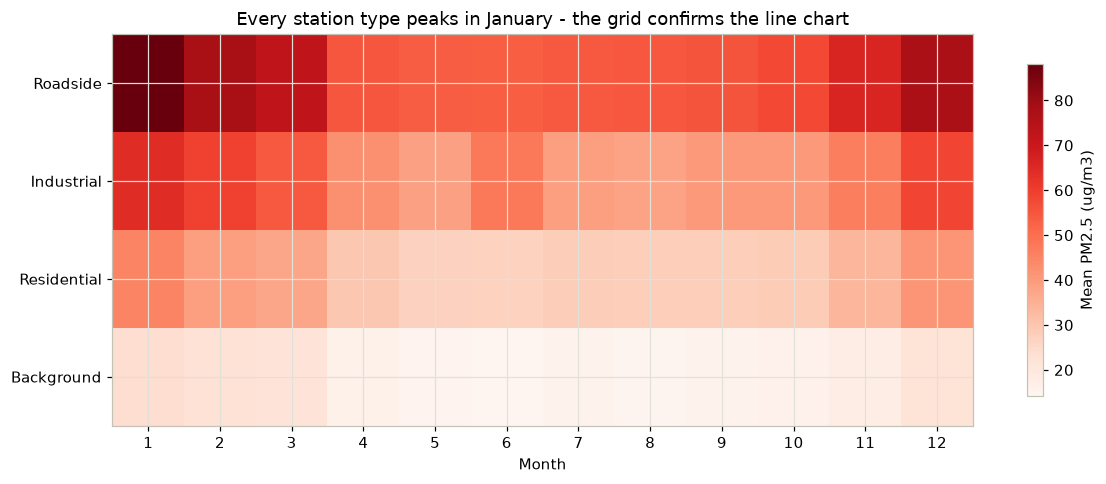

In [3]:
grid = aq.groupby(["station_type", "month"])["pm2_5"].mean().unstack()[range(1, 13)].loc[STATION_TYPE_ORDER]

fig, ax = plt.subplots(figsize=(11, 4.5))
im = ax.imshow(grid.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(12))
ax.set_xticklabels(range(1, 13))
ax.set_yticks(range(len(STATION_TYPE_ORDER)))
ax.set_yticklabels(STATION_TYPE_ORDER)
ax.set_xlabel("Month")
ax.set_title("Every station type peaks in January - the grid confirms the line chart")
fig.colorbar(im, ax=ax, shrink=0.85, label="Mean PM2.5 (ug/m3)")
fig.tight_layout()
plt.show()

This is the same information as the main lesson's line chart, in a different shape. Neither is "more correct" - the line chart makes the *trend* easier to see, the heatmap makes the *full grid of 48 numbers* easier to scan at once. Part of multivariate exploration is trying more than one shape before deciding which belongs in a report.

---

## Three variables on one scatter: position and colour

A scatter plot has two positional axes. Colour can carry a third variable - here, whether each day falls in Harmattan season - on top of the wind/PM2.5 relationship from Topic 22c.

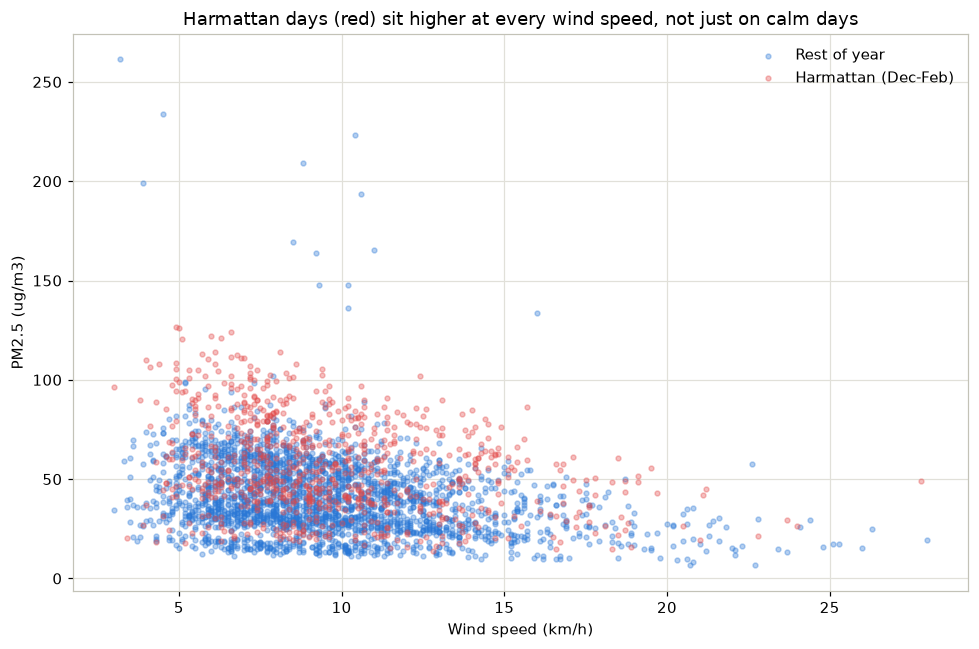

In [4]:
fig, ax = plt.subplots(figsize=(9, 6))
for is_harmattan, color, label in [(False, PALETTE["blue"], "Rest of year"),
                                     (True, PALETTE["red"], "Harmattan (Dec-Feb)")]:
    subset = aq[aq["is_harmattan"] == is_harmattan]
    ax.scatter(subset["wind_speed_kmh"], subset["pm2_5"], s=10, alpha=0.35,
               color=color, label=label)
ax.set_title("Harmattan days (red) sit higher at every wind speed, not just on calm days")
ax.set_xlabel("Wind speed (km/h)")
ax.set_ylabel("PM2.5 (ug/m3)")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

If Harmattan's effect were just "it happens to be calmer in Harmattan season," the red points would cluster at low wind speeds only. Instead they sit above the blue points across the *whole* wind-speed range - evidence that the Harmattan effect is a real, separate factor, not an artefact of the wind/PM2.5 relationship you already found.

### Try It 6 - facet by station type

Using `plt.subplots(2, 2, ...)`, build one small scatter of wind speed vs. PM2.5 per station type (one panel per type, same axis limits on every panel so they are visually comparable). Does the wind effect look equally strong at every station type, or stronger at some than others?

In [5]:
# YOUR CODE HERE

---
## Where this fits

- [Back to the main lesson](topic22_exploratory_data_analysis.ipynb)
- Previous: [22c - Bivariate exploration](topic22c_bivariate_exploration.ipynb)
- Next: [22e - From patterns to insights](topic22e_patterns_to_insights.ipynb)